# Feature Engineering for Pass/Fail Clustering
K-Means (k = 2, `random_state=42`) on student data, **before** and **after** feature engineering.

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, silhouette_score, confusion_matrix

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
df = pd.read_csv('students_dataset.csv')
print(df.shape)
df.head()

(600, 7)


,study_hours_per_week,attendance_pct,previous_grade,assignments_done_pct,sleep_hours,absences,actual
0,10.765100,73.179949,68.338955,74.195911,8.370910,8,Pass
1,2.107447,68.276768,56.059828,72.322099,7.271699,16,Fail
2,14.825146,88.945197,71.570000,86.817146,9.266308,0,Pass
3,9.879496,86.807741,73.009585,79.311205,5.828393,8,Pass
4,0.000000,59.837773,42.326410,42.928179,5.954226,12,Fail


## Rule 1: remove `actual` first and keep it aside
It is used **only** at the very end to measure accuracy.

In [4]:
y_text = df.pop('actual')                    # removed right after loading
y = (y_text == 'Pass').astype(int)           # 1 = Pass, 0 = Fail (evaluation only)
print('Columns left:', list(df.columns))
print(y_text.value_counts().to_dict())

Columns left: ['study_hours_per_week', 'attendance_pct', 'previous_grade', 'assignments_done_pct', 'sleep_hours', 'absences']
{'Pass': 390, 'Fail': 210}


## Step 1: Clean (duplicates and empty cells)

In [5]:
n_dup = df.duplicated().sum()
n_na = df.isna().sum().sum()
print('Duplicates before:', n_dup, '| Empty cells before:', n_na)
keep = ~df.duplicated()
df = df[keep]; y = y[keep]                    # keep y aligned with df
df = df.fillna(df.median())
print('Duplicates after :', df.duplicated().sum(), '| Empty cells after :', df.isna().sum().sum(), '| shape:', df.shape)

Duplicates before: 0 | Empty cells before: 0
Duplicates after : 0 | Empty cells after : 0 | shape: (600, 6)


## Step 2: Fix wrong values
Percentages must be 0-100, hours and counts must not be negative.

In [6]:
pct_cols = ['attendance_pct', 'assignments_done_pct']
nonneg_cols = ['study_hours_per_week', 'sleep_hours', 'absences']
bad_pct = ((df[pct_cols] < 0) | (df[pct_cols] > 100)).sum().sum()
bad_neg = (df[nonneg_cols] < 0).sum().sum()
print('Out-of-range percentages:', bad_pct, '| Negative hours/counts:', bad_neg)
df[pct_cols] = df[pct_cols].clip(0, 100)
df[nonneg_cols] = df[nonneg_cols].clip(lower=0)
df.describe().T[['min', 'max']]

Out-of-range percentages: 0 | Negative hours/counts: 0


,min,max
study_hours_per_week,0.000000,23.643313
attendance_pct,51.702373,100.000000
previous_grade,24.310027,100.000000
assignments_done_pct,35.336663,100.000000
sleep_hours,4.044106,10.000000
absences,0.000000,19.000000


In [7]:
# Baseline feature set = the 6 cleaned original features
X_before = df.copy()

## Step 3: Add 3 new features (built only from feature columns, never from `actual`)
| Feature | Formula | Why it should matter |
|---|---|---|
| `engagement_score` | (attendance_pct + assignments_done_pct) / 2 | Students who attend class and submit homework are better prepared. |
| `risk_count` | count of: study < 2 h, attendance < 70 %, previous grade < 50, absences >= 10 | The more warning signs a student has, the more likely they are to fail. |
| `sleep_deviation` | abs(sleep_hours - 8) | Too little or too much sleep can hurt concentration and exam results. |

In [8]:
df['engagement_score'] = (df.attendance_pct + df.assignments_done_pct) / 2
df['risk_count'] = ((df.study_hours_per_week < 2).astype(int)
                    + (df.attendance_pct < 70).astype(int)
                    + (df.previous_grade < 50).astype(int)
                    + (df.absences >= 10).astype(int))
df['sleep_deviation'] = (df.sleep_hours - 8).abs()
NEW_FEATURES = ['engagement_score', 'risk_count', 'sleep_deviation']
df[NEW_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
engagement_score,600.0,76.885662,11.148578,46.253877,69.274875,76.772637,84.670083,100.000000
risk_count,600.0,0.638333,1.025972,0.000000,0.000000,0.000000,1.000000,4.000000
sleep_deviation,600.0,1.169099,0.797928,0.002077,0.483858,1.042848,1.713761,3.955894


## Step 4: Remove repeated features
A feature is removed when it repeats another one. Two checks are used:
1. **Correlation above 0.85** (the rule from the criteria).
2. **Redundancy**: a feature that only re-shapes another column, so it carries the same information. This is checked with the correlation list (pairs close to the limit) and the **VIF** (variance inflation factor: how well one feature can be rebuilt from all the others; above about 5 means it is mostly repeated, `inf` means an exact copy).

                      study_hours_per_week  attendance_pct  previous_grade  assignments_done_pct  sleep_hours  absences  engagement_score  risk_count  sleep_deviation
study_hours_per_week                 1.000           0.567           0.627                 0.607        0.255    -0.528             0.670      -0.595           -0.216
attendance_pct                       0.567           1.000           0.583                 0.539        0.241    -0.495             0.829      -0.675           -0.173
previous_grade                       0.627           0.583           1.000                 0.598        0.283    -0.556             0.672      -0.662           -0.238
assignments_done_pct                 0.607           0.539           0.598                 1.000        0.243    -0.543             0.918      -0.554           -0.215
sleep_hours                          0.255           0.241           0.283                 0.243        1.000    -0.228             0.275      -0.239           -0.81

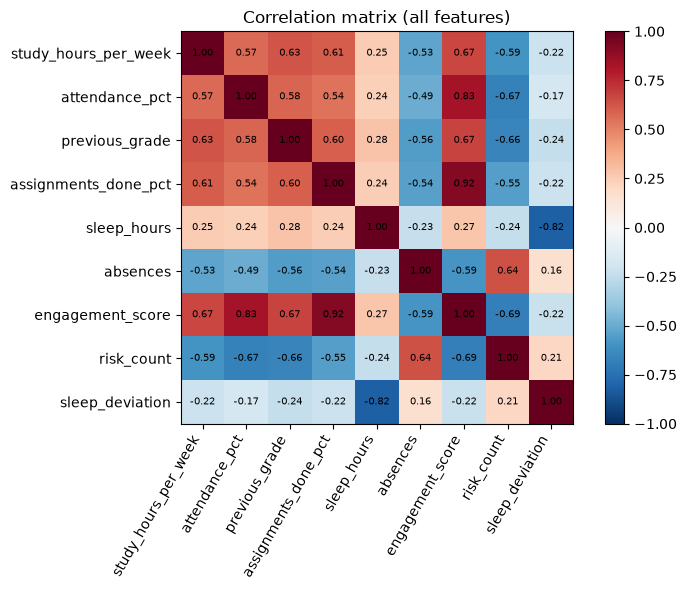

In [9]:
corr = df.corr()
print(corr.round(3))
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > 0.85]
near  = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i+1:] if 0.80 < abs(corr.loc[a, b]) <= 0.85]
print('\nRule 1 - pairs ABOVE 0.85 :', [(a, b, round(c, 3)) for a, b, c in pairs])
print('Near the limit (0.80-0.85):', [(a, b, round(c, 3)) for a, b, c in near])

plt.figure(figsize=(8, 6)); plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=60, ha='right'); plt.yticks(range(len(corr)), corr.columns)
for (i, j), v in np.ndenumerate(corr.values): plt.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7)
plt.title('Correlation matrix (all features)'); plt.tight_layout(); plt.show()

In [10]:
def vif(X):
    out = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = np.inf if r2 > 0.999999 else 1 / (1 - r2)
    return pd.Series(out, name='VIF')

print('VIF before removal (inf = exact copy of other columns):')
vif(df).round(2)

VIF before removal (inf = exact copy of other columns):


study_hours_per_week    2.10
attendance_pct           inf
previous_grade          2.31
assignments_done_pct     inf
sleep_hours             3.12
absences                1.92
engagement_score         inf
risk_count              2.70
sleep_deviation         3.02
Name: VIF, dtype: float64

`attendance_pct`, `assignments_done_pct` and `engagement_score` have an infinite VIF because `engagement_score` is exactly their average, so one of them must go. The correlation list also shows `sleep_hours` and `sleep_deviation` at about -0.815, just under the 0.85 limit: `sleep_deviation` is calculated from `sleep_hours` alone, so it is the same information in a different shape (redundancy).

In [11]:
# Rule 1: correlation above 0.85  -> engagement_score vs assignments_done_pct (0.918). Keep the new feature, drop the original.
# Rule 2: redundancy              -> sleep_deviation is built only from sleep_hours (corr about -0.815). Keep the new feature, drop the original.
removed = {'assignments_done_pct': 'Rule 1: correlation 0.918 with engagement_score (above 0.85)',
           'sleep_hours':          'Rule 2: redundant, sleep_deviation is calculated only from it (correlation -0.815)'}
df_final = df.drop(columns=list(removed))
print(pd.Series(removed).to_string())
print('\nFinal features:', list(df_final.columns))
print('\nLargest remaining correlation (should be below 0.85):', round(df_final.corr().abs().where(~np.eye(df_final.shape[1], dtype=bool)).max().max(), 3))
print('\nVIF after removal:'); vif(df_final).round(2)

assignments_done_pct    Rule 1: correlation 0.918 with engagement_scor...
sleep_hours             Rule 2: redundant, sleep_deviation is calculat...

Final features: ['study_hours_per_week', 'attendance_pct', 'previous_grade', 'absences', 'engagement_score', 'risk_count', 'sleep_deviation']

Largest remaining correlation (should be below 0.85): 0.829

VIF after removal:


study_hours_per_week    2.10
attendance_pct          3.48
previous_grade          2.31
absences                1.90
engagement_score        4.48
risk_count              2.70
sleep_deviation         1.07
Name: VIF, dtype: float64

## Step 5: Scale with `StandardScaler`, then K-Means (k = 2, `random_state=42`)
K-Means cluster numbers (0/1) are arbitrary, so each cluster is matched to Pass/Fail in the way that gives the higher accuracy (the same rule for Before and After).

In [12]:
def evaluate(X, name):
    Xs = StandardScaler().fit_transform(X)
    km = KMeans(n_clusters=2, random_state=42, n_init=10).fit(Xs)
    pred = km.labels_
    if accuracy_score(y, 1 - pred) > accuracy_score(y, pred):   # match cluster ids to Fail/Pass
        pred = 1 - pred
    return dict(name=name, n_features=X.shape[1], accuracy=accuracy_score(y, pred),
                silhouette=silhouette_score(Xs, pred), cm=confusion_matrix(y, pred, labels=[0, 1]))

before = evaluate(X_before, 'Before')
after  = evaluate(df_final, 'After')
table = pd.DataFrame({'Before': [before['accuracy'], before['silhouette']],
                      'After':  [after['accuracy'],  after['silhouette']]},
                     index=['Accuracy', 'Silhouette']).round(3)
table['Change'] = (table['After'] - table['Before']).round(3)
table

,Before,After,Change
Accuracy,0.822,0.847,0.025
Silhouette,0.295,0.338,0.043


In [13]:
for r in (before, after):
    print(r['name'], '- confusion matrix (rows = actual Fail/Pass, cols = predicted Fail/Pass)')
    print(pd.DataFrame(r['cm'], index=['Actually Fail', 'Actually Pass'], columns=['Predicted Fail', 'Predicted Pass']), '\n')
print('Extra students correct after:', int(round((after['accuracy'] - before['accuracy']) * len(y))))

Before - confusion matrix (rows = actual Fail/Pass, cols = predicted Fail/Pass)
               Predicted Fail  Predicted Pass
Actually Fail             191              19
Actually Pass              88             302 

After - confusion matrix (rows = actual Fail/Pass, cols = predicted Fail/Pass)
               Predicted Fail  Predicted Pass
Actually Fail             161              49
Actually Pass              43             347 

Extra students correct after: 15


## Compare the three new features
Same pipeline (scaling + K-Means), changing only which new features are added. `actual` is used for scoring only.
- **Table 1** applies the Step 4 removals automatically (drop `assignments_done_pct` when `engagement_score` is used; drop `sleep_hours` when `sleep_deviation` is used).
- **Table 2** shows the same combinations *without* removing anything (new features simply added to the original 6).

In [14]:
import itertools
orig = list(X_before.columns)

def build_set(feats, apply_step4=True):
    cols = list(orig)
    if apply_step4:
        if 'engagement_score' in feats: cols.remove('assignments_done_pct')   # Rule 1
        if 'sleep_deviation'  in feats: cols.remove('sleep_hours')            # Rule 2
    return cols + list(feats)

def metrics(X, name):
    r = evaluate(X, name); (tn, fp), (fn, tp) = r['cm']
    return {'Feature set': name, '# features': X.shape[1], 'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn),
            'Accuracy': round(r['accuracy'], 3), 'Silhouette': round(r['silhouette'], 3)}

def compare(apply_step4):
    rows = [metrics(X_before, 'Before (original 6)')]
    for k in (1, 2, 3):
        for feats in itertools.combinations(NEW_FEATURES, k):
            tag = ' + '.join(feats) + ('  (FINAL)' if k == 3 else '')
            rows.append(metrics(df[build_set(feats, apply_step4)], tag))
    t = pd.DataFrame(rows).set_index('Feature set')
    t['Acc. change vs Before'] = (t['Accuracy'] - t.loc['Before (original 6)', 'Accuracy']).round(3)
    t['Sil. change vs Before'] = (t['Silhouette'] - t.loc['Before (original 6)', 'Silhouette']).round(3)
    return t

feature_cmp = compare(True)
print('TABLE 1 - with Step 4 removals applied'); feature_cmp

TABLE 1 - with Step 4 removals applied


,# features,TP,TN,FP,FN,Accuracy,Silhouette,Acc. change vs Before,Sil. change vs Before
Feature set,,,,,,,,,
Before (original 6),6,302,191,19,88,0.822,0.295,0.000,0.000
engagement_score,6,289,192,18,101,0.802,0.310,-0.020,0.015
risk_count,7,339,176,34,51,0.858,0.312,0.036,0.017
sleep_deviation,6,299,192,18,91,0.818,0.295,-0.004,0.000
engagement_score + risk_count,7,339,168,42,51,0.845,0.330,0.023,0.035
engagement_score + sleep_deviation,6,283,193,17,107,0.793,0.308,-0.029,0.013
risk_count + sleep_deviation,7,340,173,37,50,0.855,0.315,0.033,0.020
engagement_score + risk_count + sleep_deviation (FINAL),7,347,161,49,43,0.847,0.338,0.025,0.043


In [15]:
print('TABLE 2 - same combinations WITHOUT removing anything (new features added to the original 6)')
compare(False)

TABLE 2 - same combinations WITHOUT removing anything (new features added to the original 6)


,# features,TP,TN,FP,FN,Accuracy,Silhouette,Acc. change vs Before,Sil. change vs Before
Feature set,,,,,,,,,
Before (original 6),6,302,191,19,88,0.822,0.295,0.000,0.000
engagement_score,7,282,194,16,108,0.793,0.313,-0.029,0.018
risk_count,7,339,176,34,51,0.858,0.312,0.036,0.017
sleep_deviation,7,300,191,19,90,0.818,0.275,-0.004,-0.020
engagement_score + risk_count,8,329,177,33,61,0.843,0.321,0.021,0.026
engagement_score + sleep_deviation,8,284,194,16,106,0.797,0.289,-0.025,-0.006
risk_count + sleep_deviation,8,336,169,41,54,0.842,0.294,0.020,-0.001
engagement_score + risk_count + sleep_deviation (FINAL),9,318,179,31,72,0.828,0.297,0.006,0.002


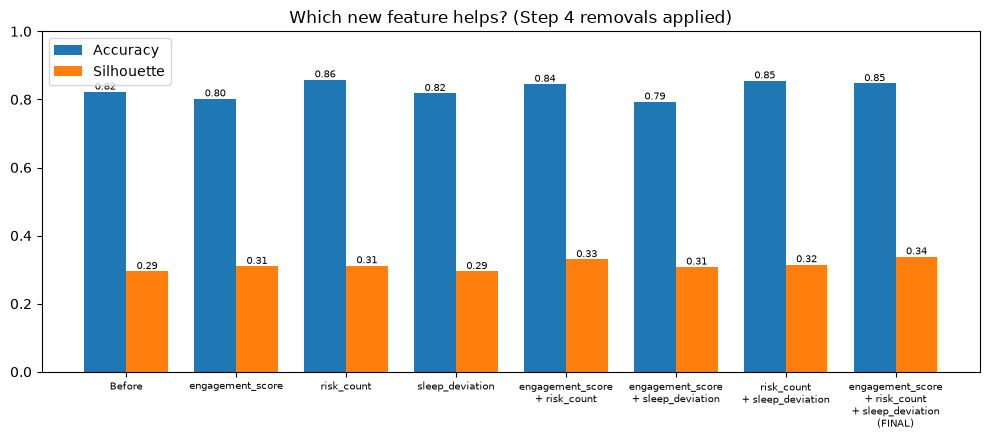

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(feature_cmp)); w = 0.38
b1 = ax.bar(x - w/2, feature_cmp['Accuracy'],   w, label='Accuracy')
b2 = ax.bar(x + w/2, feature_cmp['Silhouette'], w, label='Silhouette')
ax.set_xticks(x, [s.replace(' + ', '\n+ ').replace('  (FINAL)', '\n(FINAL)').replace('Before (original 6)', 'Before') for s in feature_cmp.index], fontsize=7)
ax.set_ylim(0, 1); ax.legend(); ax.set_title('Which new feature helps? (Step 4 removals applied)')
ax.bar_label(b1, fmt='%.2f', fontsize=7); ax.bar_label(b2, fmt='%.2f', fontsize=7)
plt.tight_layout(); plt.show()

### Step 4 choice for the sleep columns: keep both, or drop `sleep_hours`?

In [17]:
keep_both = [c for c in orig if c != 'assignments_done_pct'] + NEW_FEATURES      # corr rule only
drop_sleep = list(df_final.columns)                                                # corr rule + redundancy rule
opt = pd.DataFrame([metrics(df[keep_both], 'Keep both sleep_hours and sleep_deviation'),
                    metrics(df[drop_sleep], 'Drop sleep_hours (FINAL)')]).set_index('Feature set')

# Round the VIF series first, then extract the values
vif_keep_both = vif(df[keep_both]).round(2)
vif_drop_sleep = vif(df[drop_sleep]).round(2)

opt['Largest VIF'] = [vif_keep_both.max(), vif_drop_sleep.max()]
opt['VIF of sleep_deviation'] = [vif_keep_both['sleep_deviation'], vif_drop_sleep['sleep_deviation']]
opt

,# features,TP,TN,FP,FN,Accuracy,Silhouette,Largest VIF,VIF of sleep_deviation
Feature set,,,,,,,,,
Keep both sleep_hours and sleep_deviation,8,343,166,44,47,0.848,0.308,4.48,3.02
Drop sleep_hours (FINAL),7,347,161,49,43,0.847,0.338,4.48,1.07


**Reading the comparison**
- On their own, `engagement_score` (0.802) and `sleep_deviation` (0.818) do not beat the Before accuracy (0.822). `risk_count` is the strongest single feature (0.858).
- The three together give the **clearest groups** (silhouette 0.338, the highest of all combinations) and accuracy 0.847.
- `risk_count` + `sleep_deviation` reaches a slightly higher accuracy (0.855) but a lower silhouette (0.315).
- Dropping `sleep_hours` keeps accuracy about the same as keeping both (0.847 vs 0.848) and makes the groups clearer (0.338 vs 0.308), and it removes the repeated information.

## Bonus: `np.log1p` on a skewed column

In [18]:
print('absences skew before:', round(df_final.absences.skew(), 3), '| after log1p:', round(np.log1p(df_final.absences).skew(), 3))
d_log = df_final.copy(); d_log['absences'] = np.log1p(d_log['absences'])
r_log = evaluate(d_log, 'After + log1p(absences)')
print('Accuracy  ', round(r_log['accuracy'], 3), 'vs', round(after['accuracy'], 3), '(without log)')
print('Silhouette', round(r_log['silhouette'], 3), 'vs', round(after['silhouette'], 3), '(without log)')
helped = (r_log['accuracy'] > after['accuracy'] + 0.0005) and (r_log['silhouette'] >= after['silhouette'])
print('Did log1p help?', 'Yes' if helped else 'No - not used in the final dataset')

absences skew before: 0.273 | after log1p: -1.061
Accuracy   0.847 vs 0.847 (without log)
Silhouette 0.319 vs 0.338 (without log)
Did log1p help? No - not used in the final dataset


`absences` is only mildly skewed (skew about 0.27), and `log1p` over-corrected it to about -1.06. On the final data accuracy stayed at 0.847 and it lowered the silhouette score (0.338 to 0.319). **It did not help, so it is not used in the final dataset.**

# Before vs After: full comparison
Everything below uses the same pipeline (`StandardScaler` + K-Means, k = 2, `random_state=42`). `actual` is used only to score the clusters.

**How to read the confusion matrix** (Positive = **Pass**, Negative = **Fail**):
| | Predicted Fail | Predicted Pass |
|---|---|---|
| **Actually Fail** | TN (Fail correctly found) | FP (Fail wrongly called Pass) |
| **Actually Pass** | FN (Pass wrongly called Fail) | TP (Pass correctly found) |

In [19]:
def full_metrics(X, name):
    r = evaluate(X, name)
    (tn, fp), (fn, tp) = r['cm']                 # rows = actual Fail/Pass, cols = predicted Fail/Pass
    return {'Scenario': name, 'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn),
            'Accuracy': r['accuracy'], 'Precision (Pass)': tp / (tp + fp),
            'Recall (Pass)': tp / (tp + fn), 'Silhouette': r['silhouette']}

# Bonus np.log1p on `absences`, applied to BOTH datasets
def with_log(X):
    X = X.copy(); X['absences'] = np.log1p(X['absences']); return X

scenarios = {
    'Before':                    X_before,
    'Before + log1p(absences)':  with_log(X_before),
    'After':                     df_final,
    'After + log1p(absences)':   with_log(df_final),
}
results = pd.DataFrame([full_metrics(X, n) for n, X in scenarios.items()]).set_index('Scenario')
results.round(3)

,TP,TN,FP,FN,Accuracy,Precision (Pass),Recall (Pass),Silhouette
Scenario,,,,,,,,
Before,302,191,19,88,0.822,0.941,0.774,0.295
Before + log1p(absences),263,201,9,127,0.773,0.967,0.674,0.297
After,347,161,49,43,0.847,0.876,0.890,0.338
After + log1p(absences),343,165,45,47,0.847,0.884,0.879,0.319


### 1. Confusion matrix counts: Before vs After

In [20]:
cm_table = results.loc[['Before', 'After'], ['TP', 'TN', 'FP', 'FN']].T
cm_table['Change (After - Before)'] = cm_table['After'] - cm_table['Before']
cm_table['Good or bad?'] = ['more is better', 'more is better', 'fewer is better', 'fewer is better']
print('Total students:', len(y), '| Before correct (TP+TN):', int(results.loc['Before', ['TP','TN']].sum()),
      '| After correct (TP+TN):', int(results.loc['After', ['TP','TN']].sum()))
cm_table

Total students: 600 | Before correct (TP+TN): 493 | After correct (TP+TN): 508


Scenario,Before,After,Change (After - Before),Good or bad?
TP,302,347,45,more is better
TN,191,161,-30,more is better
FP,19,49,30,fewer is better
FN,88,43,-45,fewer is better


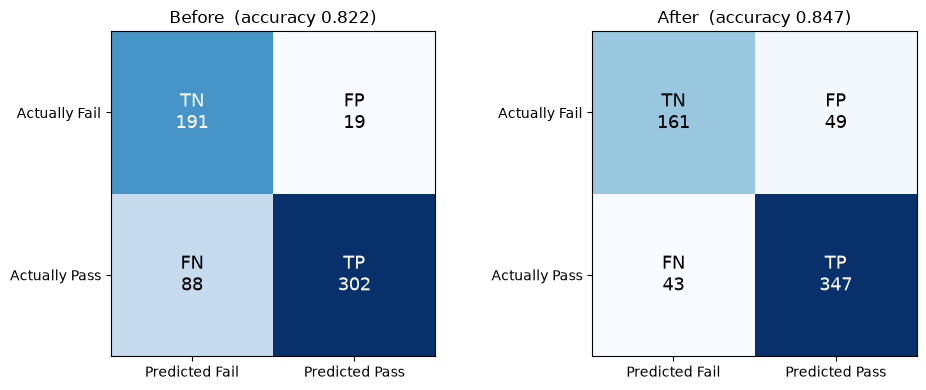

In [21]:
def plot_confusion(save=None):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name in zip(axes, ['Before', 'After']):
        r = results.loc[name]
        m = np.array([[r.TN, r.FP], [r.FN, r.TP]]).astype(int)
        ax.imshow(m, cmap='Blues')
        ax.set_xticks([0, 1], ['Predicted Fail', 'Predicted Pass']); ax.set_yticks([0, 1], ['Actually Fail', 'Actually Pass'])
        for (i, j), v in np.ndenumerate(m):
            tag = [['TN', 'FP'], ['FN', 'TP']][i][j]
            ax.text(j, i, f'{tag}\n{v}', ha='center', va='center', fontsize=13, color='white' if v > m.max() / 2 else 'black')
        ax.set_title(f"{name}  (accuracy {r.Accuracy:.3f})")
    plt.tight_layout()
    if save: plt.savefig(save, dpi=200)
    plt.show()
plot_confusion()

### 2. Accuracy and silhouette score: Before vs After

In [22]:
cmp = results.loc[['Before', 'After'], ['Accuracy', 'Precision (Pass)', 'Recall (Pass)', 'Silhouette']].T
cmp['Change'] = cmp['After'] - cmp['Before']
cmp['Better?'] = np.where(cmp['Change'] > 0.0005, 'Better', np.where(cmp['Change'] < -0.0005, 'Worse', 'Same'))
cmp.round(3)

Scenario,Before,After,Change,Better?
Accuracy,0.822,0.847,0.025,Better
Precision (Pass),0.941,0.876,-0.065,Worse
Recall (Pass),0.774,0.890,0.115,Better
Silhouette,0.295,0.338,0.043,Better


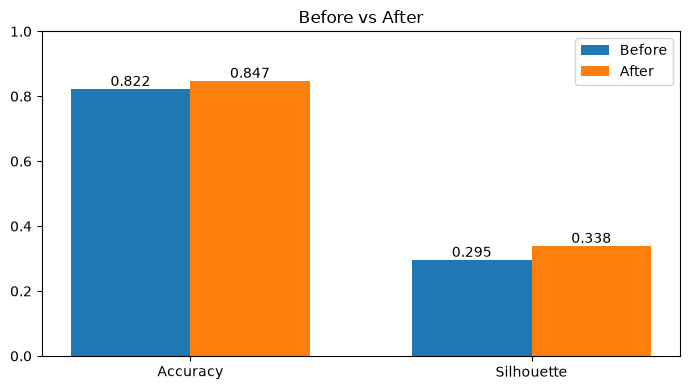

In [23]:
def plot_bars(save=None):
    fig, ax = plt.subplots(figsize=(7, 4)); x = np.arange(2); w = 0.35
    b = ax.bar(x - w/2, results.loc['Before', ['Accuracy', 'Silhouette']], w, label='Before')
    a = ax.bar(x + w/2, results.loc['After',  ['Accuracy', 'Silhouette']], w, label='After')
    ax.set_xticks(x, ['Accuracy', 'Silhouette']); ax.set_ylim(0, 1); ax.legend(); ax.set_title('Before vs After')
    ax.bar_label(b, fmt='%.3f'); ax.bar_label(a, fmt='%.3f')
    plt.tight_layout()
    if save: plt.savefig(save, dpi=200)
    plt.show()
plot_bars()

### 3. Effect of `np.log1p` on `absences` (on both datasets)

In [24]:
print('Skew of absences  | original:', round(df_final.absences.skew(), 3), '| after log1p:', round(np.log1p(df_final.absences).skew(), 3))
log_cmp = results[['TP', 'TN', 'FP', 'FN', 'Accuracy', 'Silhouette']].copy()
for tag in ('Before', 'After'):
    log_cmp.loc[f'{tag} + log1p(absences)', 'Accuracy change vs no-log']   = results.loc[f'{tag} + log1p(absences)', 'Accuracy']   - results.loc[tag, 'Accuracy']
    log_cmp.loc[f'{tag} + log1p(absences)', 'Silhouette change vs no-log'] = results.loc[f'{tag} + log1p(absences)', 'Silhouette'] - results.loc[tag, 'Silhouette']
log_cmp.round(3)

Skew of absences  | original: 0.273 | after log1p: -1.061


,TP,TN,FP,FN,Accuracy,Silhouette,Accuracy change vs no-log,Silhouette change vs no-log
Scenario,,,,,,,,
Before,302,191,19,88,0.822,0.295,NaN,NaN
Before + log1p(absences),263,201,9,127,0.773,0.297,-0.048,0.002
After,347,161,49,43,0.847,0.338,NaN,NaN
After + log1p(absences),343,165,45,47,0.847,0.319,0.000,-0.019


### 4. Summary of every comparison

In [25]:
summary = results[['TP', 'TN', 'FP', 'FN', 'Accuracy', 'Precision (Pass)', 'Recall (Pass)', 'Silhouette']].round(3)
best_acc = summary['Accuracy'].idxmax(); best_sil = summary['Silhouette'].idxmax()
print('Highest accuracy  :', best_acc, summary.loc[best_acc, 'Accuracy'])
print('Highest silhouette:', best_sil, summary.loc[best_sil, 'Silhouette'])
summary

Highest accuracy  : After 0.847
Highest silhouette: After 0.338


,TP,TN,FP,FN,Accuracy,Precision (Pass),Recall (Pass),Silhouette
Scenario,,,,,,,,
Before,302,191,19,88,0.822,0.941,0.774,0.295
Before + log1p(absences),263,201,9,127,0.773,0.967,0.674,0.297
After,347,161,49,43,0.847,0.876,0.890,0.338
After + log1p(absences),343,165,45,47,0.847,0.884,0.879,0.319


### How to read these results
- **Confusion matrix:** After feature engineering, TP went up 302 to 347 and FN went down 88 to 43, so more passing students are found. The cost is that TN went down 191 to 161 and FP went up 19 to 49, so more failing students are wrongly called Pass. Net result: 15 more students correct (493 to 508), so accuracy rises 0.822 to 0.847.
- **Precision vs recall (Pass):** Recall of Pass rises (0.774 to 0.890) but precision falls (0.941 to 0.876). Before, the model was cautious about calling anyone Pass; after, it is more balanced.
- **Silhouette:** 0.295 to 0.338, so the two groups are clearer and further apart.
- **`np.log1p(absences)`:** On the Before data it hurt accuracy (0.822 to 0.773). On the After data accuracy stayed at 0.847 and silhouette fell (0.338 to 0.319). It does not help, so it is **not** used in the final dataset.

## Save the new dataset

In [26]:
new_df = df_final.copy()
new_df.to_csv('students_dataset_engineered.csv', index=False)                 # features only (what K-Means saw)
scaled = pd.DataFrame(StandardScaler().fit_transform(new_df), columns=new_df.columns)
scaled.to_csv('students_dataset_engineered_scaled.csv', index=False)         # standardized version
with_actual = new_df.copy(); with_actual['actual'] = y_text.loc[new_df.index].values   # added back AFTER modelling, for reference only
with_actual.to_csv('students_dataset_engineered_with_actual.csv', index=False)
print(new_df.shape); new_df.head()

(600, 7)


,study_hours_per_week,attendance_pct,previous_grade,absences,engagement_score,risk_count,sleep_deviation
0,10.765100,73.179949,68.338955,8,73.687930,0,0.370910
1,2.107447,68.276768,56.059828,16,70.299434,2,0.728301
2,14.825146,88.945197,71.570000,0,87.881171,0,1.266308
3,9.879496,86.807741,73.009585,8,83.059473,0,2.171607
4,0.000000,59.837773,42.326410,12,51.382976,4,2.045774


## Save all comparison files (CSV and images)

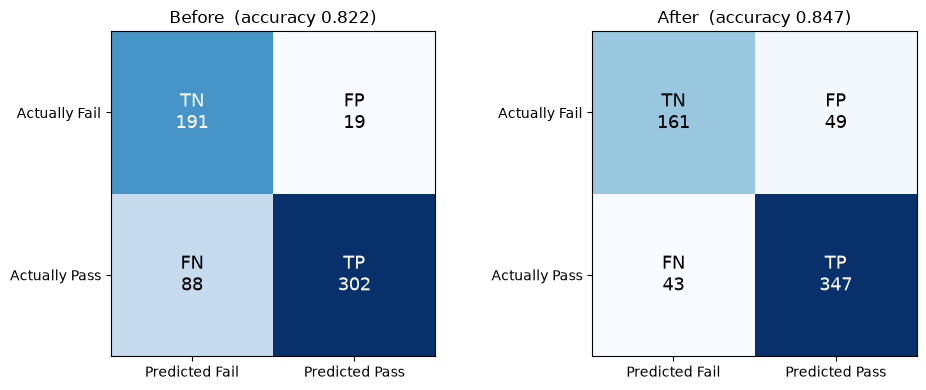

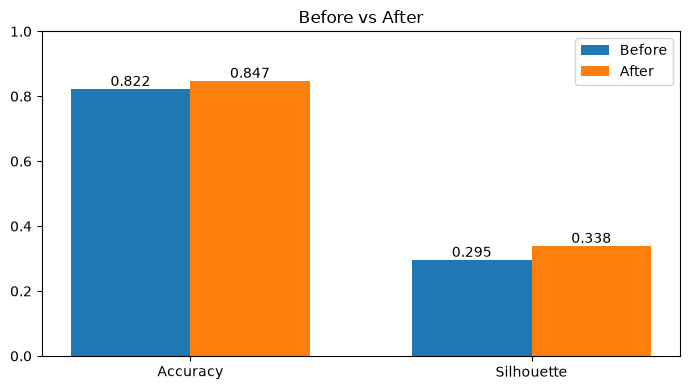

Saved. Open the Files panel (folder icon), click refresh, and download the files.


In [27]:
# CSV files
summary.to_csv('before_after_comparison.csv')
cm_table.to_csv('comparison_confusion_matrix.csv')
cmp.round(3).to_csv('comparison_metrics.csv')
log_cmp.round(3).to_csv('comparison_log1p.csv')
feature_cmp.to_csv('comparison_three_features.csv')
corr.round(3).to_csv('correlation_matrix.csv')

# Images
plot_confusion(save='comparison_confusion_matrix.png')
plot_bars(save='comparison_accuracy_silhouette.png')

fig, ax = plt.subplots(figsize=(11, 4.2)); x = np.arange(len(feature_cmp)); w = 0.38
b1 = ax.bar(x - w/2, feature_cmp['Accuracy'], w, label='Accuracy'); b2 = ax.bar(x + w/2, feature_cmp['Silhouette'], w, label='Silhouette')
ax.set_xticks(x, [s.replace(' + ', '\n+ ').replace('  (FINAL)', '\n(FINAL)').replace('Before (original 6)', 'Before') for s in feature_cmp.index], fontsize=7)
ax.set_ylim(0, 1); ax.legend(); ax.set_title('Comparison of the three new features (Step 4 removals applied)')
ax.bar_label(b1, fmt='%.2f', fontsize=7); ax.bar_label(b2, fmt='%.2f', fontsize=7)
plt.tight_layout(); plt.savefig('comparison_three_features.png', dpi=200); plt.close()

plt.figure(figsize=(8, 6)); plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=60, ha='right'); plt.yticks(range(len(corr)), corr.columns)
for (i, j), v in np.ndenumerate(corr.values): plt.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7)
plt.title('Correlation matrix (all features)'); plt.tight_layout(); plt.savefig('correlation_matrix.png', dpi=200); plt.close()

tbl = summary.reset_index()
fig, ax = plt.subplots(figsize=(12, 2.6)); ax.axis('off')
t = ax.table(cellText=tbl.values, colLabels=tbl.columns, loc='center', cellLoc='center')
t.auto_set_font_size(False); t.set_fontsize(10); t.scale(1, 1.8); t.auto_set_column_width(range(len(tbl.columns)))
for j in range(len(tbl.columns)): t[0, j].set_facecolor('#dde7f3')
plt.savefig('comparison_table.png', dpi=200, bbox_inches='tight'); plt.close()
print('Saved. Open the Files panel (folder icon), click refresh, and download the files.')